# Tutorial 0 · Quickstart: the Quantcore PDK and the live KLayout loop

This notebook is the short tour. It builds a one-qubit chip from nothing, one component per cell, and shows what
each step produces: the layout (live in KLayout), the DRC, the lumped-element (LOM) netlist and the LOM simulation.
It ends with the FEM round trip (Q3D, eigenmode/EPR and driven S21 of the qubit and its readout), a feedback step
and the fab export. Tutorials 1–3 then apply the same steps to real chips (chip 12, the IBM 5-qubit bowtie, the
17-qubit surface-code chips), and tutorial 4 closes the loop on two coupled qubits.

**The loop.**

| step | what does it | output |
|---|---|---|
| design in code | `quantcore_circuits.designer.Designer` | `design.json` (instances, routes, targets, sim groups) |
| layout | KQCircuits cells and router, wrapped by `qcc` | `build/<name>.oas` + `build/<name>.qcc.json` sidecar |
| live view | **KLive** (KLayout's klive server, port 8082) + the Quantcore KLayout plugin | KLayout reloads the file after every change |
| DRC | `assembly.drc` | errors, warnings, PDK design warnings |
| netlist | `lom.lom_from_design` (each component's LOM model maps its ports to nodes) | `CircuitModel` (nodes, C / JJ / TL / hanger branches) |
| LOM simulation | `lom.simulate`: QuCat normal modes → QuTiP dressed spectrum | f_q, α, f_r, κ, χ, g, ZZ |
| FEM | `sim_tools`: Q3D C-matrix, HFSS eigenmode/EPR, driven jobs (AEDT 2024 R1) | `build/jobs/<job>/` → `results/results.json` |
| back into the LOM | `circuit.fill.fill(model, design, job)` | FEM values replace the estimates, by net name |
| fab | `layouts.wafers.fab_export.export_fab` | fab layers only, cheese, rounded corners |

**How to run.** Open the notebook in Jupyter from the repository (conda env `qcd`). By default the designer runs
**live**: if KLayout is not open it is started (with the Quantcore plugin), and every `add` / `route` below is redrawn
there. With `QCC_LIVE=0` in the environment (or without KLayout) everything runs headless: the layout is written to
`build/` and the pictures are headless KLayout renders with the same colours. Runtime ≈ 1 min (FEM results are
read from `examples/tutorials/fem/` when kept; `RUN_FEM = True` in section 9 solves them, see the wall times there).

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

**Dashboard** (`track.start("t00")` in the setup cell): every build, DRC, LOM run, FEM job (with its pass / Δ / mesh while AEDT runs) and feedback step is recorded into `build/t00/state.json`; `scripts\dashboard.cmd` in a terminal shows it live at http://127.0.0.1:8765/ (`track.stop()` switches the recording off).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "examples" / "tutorials"))
import _tut as T                                  # tutorial helpers (tables, snapshots, FEM round trip)
T.setup("t00")                                    # working directory = repo root; pictures → examples/tutorials/img/
import _common as C                               # the design-notebook helpers (netlist / mode tables, …)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

KLAYOUT_GUI = True                                # True: open / raise the KLayout window; False: redraw an open one only
LIVE = T.live_mode(gui=KLAYOUT_GUI)               # True: KLayout via KLive; False: headless (QCC_LIVE=0)
from quantcore_circuits import track
TRACKING = track.start("t00")                     # dashboard (scripts\dashboard.cmd) follows build/t00

Headless (QCC_LIVE=0): each build writes build/<name>.oas; pictures are headless KLayout snapshots.


### The FEM part in two stages, and its switches

Every tutorial runs its FEM part in two stages:

1. **Subset check (FEM only).** `SIM_SUBSET` says which part of the chip is rendered and simulated first:
   `(qubit, readout)` pairs, e.g. `[("Q1", "R1")]` — the qubit, its λ/4 and the feedline next to it, cut by the box
   into two 50 Ω ports (`Designer.sim_subset`). You look at FEM values only — convergence, the raw C-matrix and
   eigenmodes, the FEM-filled capacitances next to their estimates — and, if they are sane and converged, go on.
   No LOM is simulated on a subset and nothing is fed back from it.
2. **The whole LOM.** Fill the subset values into the whole netlist (every other branch keeps its estimate), simulate
   the LOM on the whole netlist, compare LOM and FEM, feed back, write the revision, its DRC and its fab file.

This chip has one qubit, so the subset box *is* the chip minus its pads and stage 2 reuses the stage-1 jobs (no second
solve). `FEM_WHOLE = True` (opt-in) simulates the chip with its pads instead (the built-in group `chip`, every pad a 50 Ω port).
Tutorials 2 and 3 choose subsets of larger chips. `RUN_FEM`, `RESOLVE` (re-solve although kept results match),
`FEM_FAST` and `AEDT_MODE` are explained in section 9.

In [3]:
SIM_SUBSET = [("Q1", "R1")]      # stage 1: the (qubit, readout) pairs to render and simulate, or "whole" (with the pads)
FEM_WHOLE = False                # True (opt-in, slower): the whole chip with its pads instead of the subset
if FEM_WHOLE:
    SIM_SUBSET = "whole"
RUN_FEM = False                  # True (or a set of analyses): solve the jobs in AEDT, one at a time
RESOLVE = False                  # True (or a set of analyses): re-solve even when the kept results match
FEM_FAST = True                  # True: fast test settings (few passes, values not converged); False: converged settings
AEDT_MODE = "batch"              # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

## 1 · The PDK

`get_pdk()` returns the process design kit every build uses unless a design names another one
(`quantcore_nb_sapphire_v1` is the default; `quantcore_nb_si_v1` is kept for comparisons). It fixes:

- the **stack** used by every FEM export and analytic formula (sapphire, 650 µm, εr 10.25; Nb film);
- the **die frame** drawn on every Quantcore chip (dicing L's, alignment grids, chip boundary, optional device ID,
  brand `QCT`);
- the **pad rule**: pads and launchers sit with their outer etch edge 100 µm (the PDK `pad_edge`) from the die
  edge;
- the **junction rule**: every qubit junction is a Nb/AlOx/Nb trilayer junction with R_n in 40–50 kΩ;
- the **3/0 keep-out**, the **cheese** band and the **corner rounding** of the fab export.

Values outside the PDK margins are *flagged* as DRC design warnings, never silently changed.

In [4]:
pdk = get_pdk()
T.md(T.pdk_md(pdk))

| PDK fact | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, εr 10.25, tan δ 1e-06; Nb film 0.2 µm (a sheet in FEM), λ_L 90 nm → L_k 0.116 pH/□ |
| CPW default | centre a = 10 µm, gap b = 6 µm (≈ 50 Ω on sapphire), bends r = 100 µm |
| die frame | L dicing markers (250 µm legs, 25 µm wide, 1000/0), 3 × 3 alignment grids in the 500 µm corner squares (1001/0), chip boundary 100/0, optional device ID (700 × 300 µm), brand `QCT` |
| pad rule | outer etch edge of every bond pad / launcher **100 µm** (the design-area margin) from the die edge: `d.add(..., edge="auto")`; DRC design warning `pad_edge` otherwise |
| junction rule | Nb/AlOx/Nb trilayer: Δ = 1.4 meV, I_c·R_n = πΔ/2e; **R_n 40–50 kΩ**, qubits 4–8 GHz; nominal 0.5 × 0.6 µm = 45 kΩ → L_J 6.73 nH, C_J 15 fF; cells `Quantcore Junction` / `Quantcore Squid` (the default junction_type) |
| 3/0 keep-out | filled second-metal etch: routes = CPW footprint + 10 µm, components = etch bbox + 24 µm (or the cell's own `qcc_keepout`), other 1/0 + 9 µm |
| cheese | a band of 3 rows of 5 µm squares with 20 µm gaps around 3/0, drawn in the build (KQC `ground_grid`); **the original design's own cheese wins**; never in FEM exports |
| corner rounding | fab export only: r = min(0.25 × the polygon's shortest dimension, 10 µm) on M1, M3; junction fingers stay sharp |

The **fab layer map** is a negative mask: what is drawn is removed (etched or exposed). Layouts are drawn in KQC layer
names (`1t1_base_metal_gap_wo_grid`, `1t1_SIS_junction`, …); the fab numbers appear at the mask export (section 9).

In [5]:
T.md(T.fab_layers_md(pdk))
print(pdk.frame)
print(pdk.junction)

| fab layer | name | drawn from | meaning |
|---|---|---|---|
| 1/0 | `M1` | `base_metal_gap` | fine structure etch (negative) |
| 2/0 | `JJ_STRAIGHT` | `SIS_junction` | junction top finger |
| 3/0 | `M3` | `derived` | second-metal keep-out: filled keep-outs (KeepoutRule) |
| 4/0 | `JJ_BENT` | `SIS_junction_2` | junction second finger |
| 50/0 | `HSQ` | `hsq` | junction spacer material |
| 51/0 | `SPACER_1` | `spacer_1` | spacer gradient, shade 1 |
| 52/0 | `SPACER_2` | `spacer_2` | spacer gradient, shade 2 |
| 53/0 | `SPACER_3` | `spacer_3` | spacer gradient, shade 3 |
| 100/0 | `CHIP_BOUNDARY` | `chip_boundary` | chip boundary |
| 300/0 | `AIRBRIDGE_PADS` | `airbridge_pads` | airbridge pads |
| 301/0 | `AIRBRIDGE_BRIDGE` | `airbridge_flyover` | airbridge bridge (301/0 assumed) |
| 500/0 | `WAFER_BOUNDARY` | `wafer_boundary` | wafer boundary |
| 501/0 | `WAFER_MARKERS` | `wafer_markers` | wafer markers |
| 700/0 | `TSV` | `through_silicon_via` | through-silicon vias |
| 800/0 | `FC_M1` | `base_metal_gap` | flip-chip top chip (face 2b1) etch |
| 801/0 | `FC_BUMPS` | `indium_bump` | indium bumps |
| 802/0 | `FC_UBM` | `underbump_metallization` | under-bump metal |
| 803/0 | `FC_JJ_1` | `SIS_junction` | face 2b1 junction finger 1 |
| 804/0 | `FC_JJ_2` | `SIS_junction_2` | face 2b1 junction finger 2 |
| 1000/0 | `MARKERS_DICING` | `marker_0` | dicing markers |
| 1001/0 | `MARKERS_ALIGN` | `marker_1` | alignment markers |

DieFrame(margin=100.0, dicing_leg=250.0, dicing_width=25.0, marker_area=500.0, grid_x=(302.5, 452.5, 602.5), grid_y=(305.0, 452.5, 600.0), grid_small=5.0, grid_large=10.0, device_id=(700.0, 300.0), pad_edge=100.0, dicing_layer='marker_0', alignment_layer='marker_1', boundary_layer='chip_boundary')
JunctionProcess(material='Nb/AlOx/Nb trilayer', gap_meV=1.4, rn_target_kohm=(40.0, 50.0), rn_nominal_kohm=45.0, f_q_range_GHz=(4.0, 8.0), nominal_fingers_um=(0.5, 0.6), rn_area_ohm_um2=13500.0, cj_fF_per_um2=50.0, bent_finger_um=0.6, finger_grid_um=0.01, finger_range_um=(0.1, 2.0), spacer_gradient=True, spacer_shades=3)


## 2 · The die and the live view

`Designer(name, box=...)` starts an empty design on a 7.5 × 7.5 mm die. `live=LIVE` decides where each change goes:

- **live** — `Designer.show()` builds the chip with KQC, writes `build/t00_quickstart.oas` and its sidecar, then
  sends the file to KLayout over **KLive** (TCP `localhost:8082`, `quantcore_circuits.live.send_to_klive`). KLayout
  reloads it and keeps the view, so you watch the chip grow. If KLayout is not running it is started once
  (`live.klayout.open_klayout`, detached, so it survives a kernel restart). The Quantcore plugin's panel lists the
  components, the LOM netlist and the DRC of the same sidecar;
- **headless** — the same build and the same files, without sending; `T.snap` renders a picture with KLayout's own
  renderer.

Even the empty die has content: the PDK frame (dicing markers at the corners, alignment grids, chip boundary) and the
device ID `QS1` at the bottom centre.

<Designer t00_quickstart: 0 instances, 0 routes, live=False> → build\t00_quickstart.oas


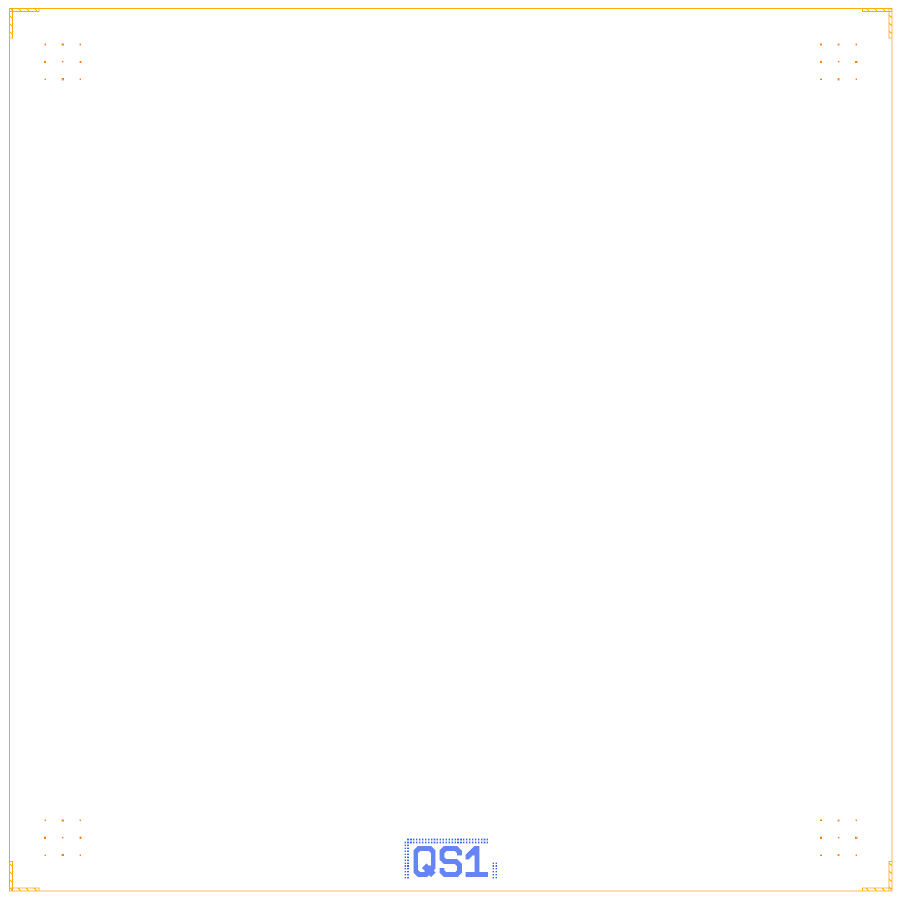

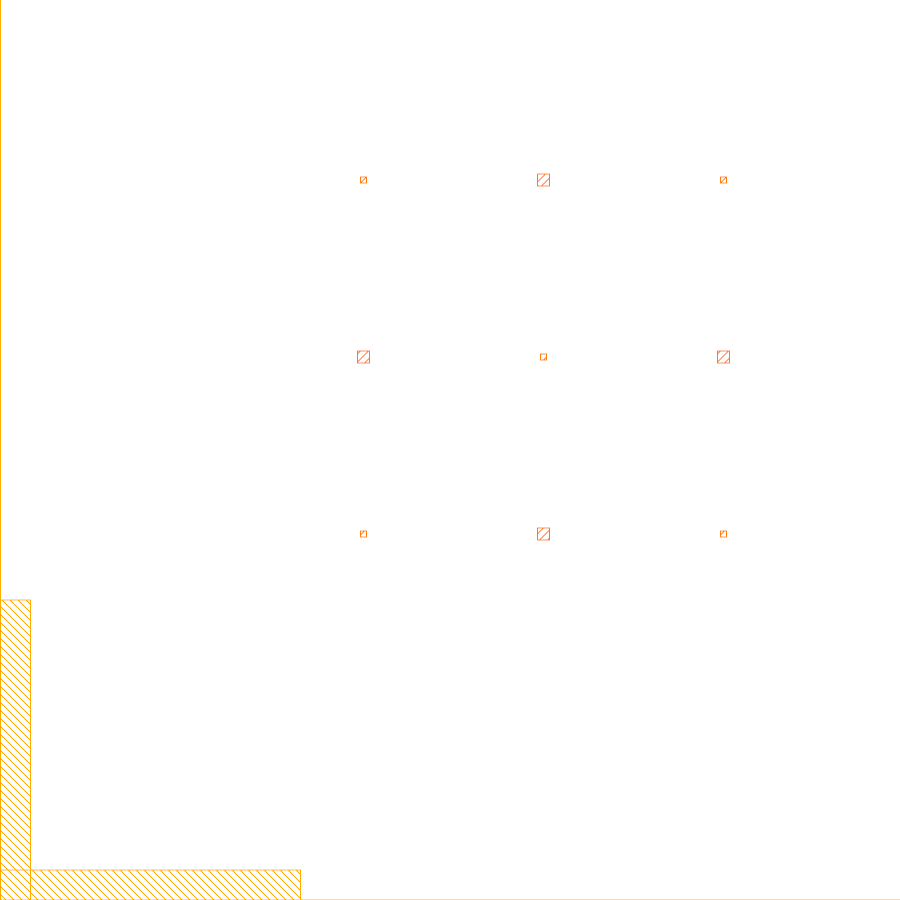

WindowsPath('examples/tutorials/img/t00_frame_corner.png')

In [6]:
d = Designer("t00_quickstart", box=(0, 0, 7500, 7500), chip={"name_chip": "QS1"}, live=LIVE)
T.built(d)                                        # live: already built and sent; headless: build now
print(d, "→", d.out)
T.snap(d, "die", size=(900, 900), width=360)
T.snap(d, "frame_corner", box=(0, 0, 750, 750), size=(900, 900), width=360)   # dicing L + 3×3 alignment grid

## 3 · Pads: the 100 µm rule

A `BondPad` is a 50 Ω launch pad with one port `a` (where a CPW attaches). `edge="auto"` applies the PDK pad rule:
the pad slides perpendicular to the nearest die edge until the outer edge of its etch is 100 µm from it; the
position along the edge is kept. Without it the DRC adds a `pad_edge` design warning.

The DRC right after placing the pads warns that their ports are dangling — nothing is connected yet.

<BondPad PAD_W ports=['a']>
PAD_W.a at (1225.0, 3750.0) · PAD_E.a at (6275.0, 3750.0) (asked for x = 1125 / 6375)


**DRC clean** — 0 errors, 2 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 2 | PAD_E.a is not connected (no route or snap)<br>PAD_W.a is not connected (no route or snap) |

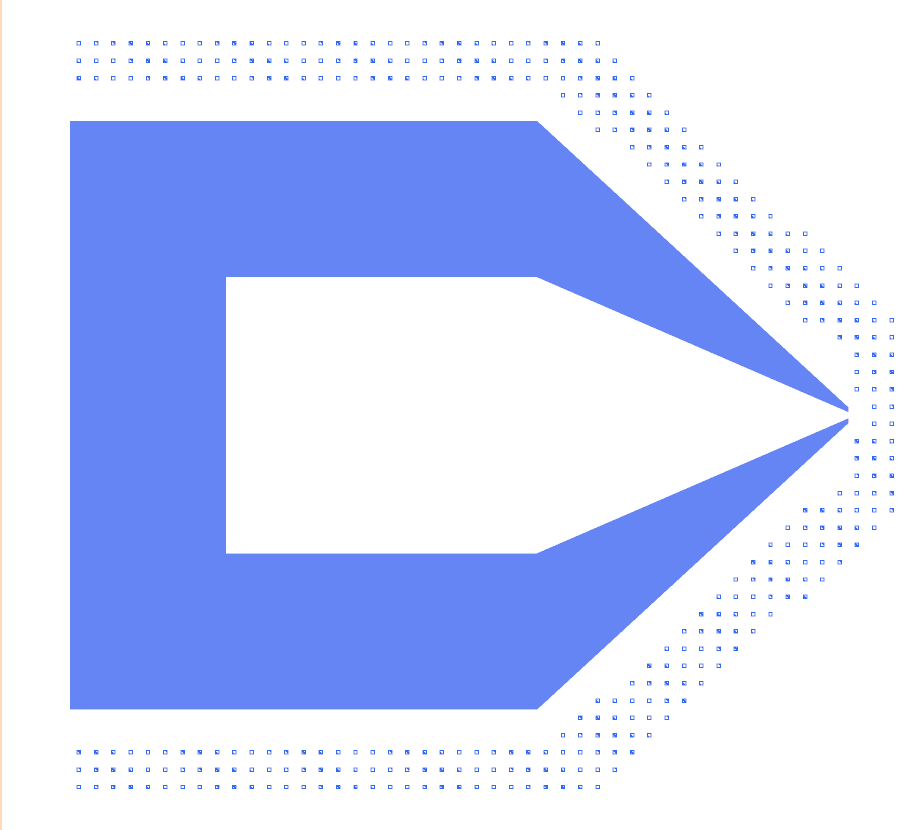

WindowsPath('examples/tutorials/img/t00_pad.png')

In [7]:
pw = d.add("PAD_W", "BondPad", at=(1125, 3750), rot=270, edge="auto")
pe = d.add("PAD_E", "BondPad", at=(6375, 3750), rot=90, edge="auto")
print(pw)
print("PAD_W.a at", C.port_xy(d, "PAD_W.a"), "· PAD_E.a at", C.port_xy(d, "PAD_E.a"), "(asked for x = 1125 / 6375)")
T.md(T.drc_md(T.drc(d)))
T.snap(d, "pad", box=(0, 3150, 1300, 4350), size=(900, 830), width=360)

## 4 · The feedline

`d.route(name, start, end)` draws a CPW between two ports (PDK default 10/6 µm, bends r = 100 µm). The handle `fl`
gives hangers later. In the LOM the whole line is one conductor node `FL` with a 50 Ω port at each pad.

In [8]:
fl = d.route("FL", pw.a, pe.a)
T.md(T.drc_md(T.drc(d)))
C.show_netlist(d.lom())

**DRC clean** — 0 errors, 0 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| – | – | 0 | – |

**2 nodes · 2 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |

**Unconnected ports:** none

## 5 · A qubit with a trilayer junction

An `Xmon` (KQC-style cross transmon, a Quantcore cell) with one readout claw `claw_n`. Its junction is the PDK
trilayer junction: `trilayer_junction("Xmon", lj_nH=...)` returns the cell parameters (`junction_type`,
`junction_params`) and the drawn junction's L_J / C_J for the LOM (fingers on the PDK grid, so L_J moves slightly).

Sizing from a target: the LOM gives the island capacitance, `size_junction(f_q, C_Σ)` the L_J for the target and the
R_n it implies. The PDK window R_n 40–50 kΩ means L_J ≈ 6.0–7.5 nH, so the *capacitance* sets the frequency: a 300 µm
cross (C_Σ ≈ 67 fF) would need R_n ≈ 66 kΩ at 5.5 GHz (flagged); the 450 µm cross used here (≈ 99 fF) lands inside.

In [9]:
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.registry import trilayer_junction

F_Q, F_R = 5.5, 7.0                               # targets (GHz)
params, junction = trilayer_junction("Xmon")      # first: the PDK nominal junction (R_n 45 kΩ)
q1 = d.add("Q1", "Xmon", at=(2975, 2100), cross_length=450, arm_width=25, gap=25, claws=["n"],
           junction=junction, **params)
print(q1)
lb = d.lom()
c_sigma = sum(b.value["estimate"] for n, b in lb.model.branches.items() if n in ("C_Q1", "Cg_Q1_claw_n"))
s = size_junction(F_Q, c_sigma, c_includes_junction=False)
print(f"C_Σ ≈ {c_sigma:.1f} fF + C_J → L_J {s.lj_nH:.2f} nH, R_n {s.rn_kohm:.1f} kΩ (in window: {s.rn_in_window})")
params, junction = trilayer_junction("Xmon", lj_nH=s.lj_nH)
q1.set(junction=junction, **params)               # one change → one rebuild (live: redrawn in KLayout)
print("drawn junction:", junction, params)

<Xmon Q1 ports=['claw_n']>
C_Σ ≈ 99.2 fF + C_J → L_J 6.92 nH, R_n 46.2 kΩ (in window: True)
drawn junction: {'Lj_nH': 6.8719, 'Cj_fF': 14.7} {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 6.920722837323593}}


The qubit's claw is still unconnected (DRC warning) and the LOM now has the island node `Q1` with its junction and
capacitances, and the claw node `Q1.claw_n`.

**DRC clean** — 0 errors, 1 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 1 | Q1.claw_n is not connected (no route or snap) |

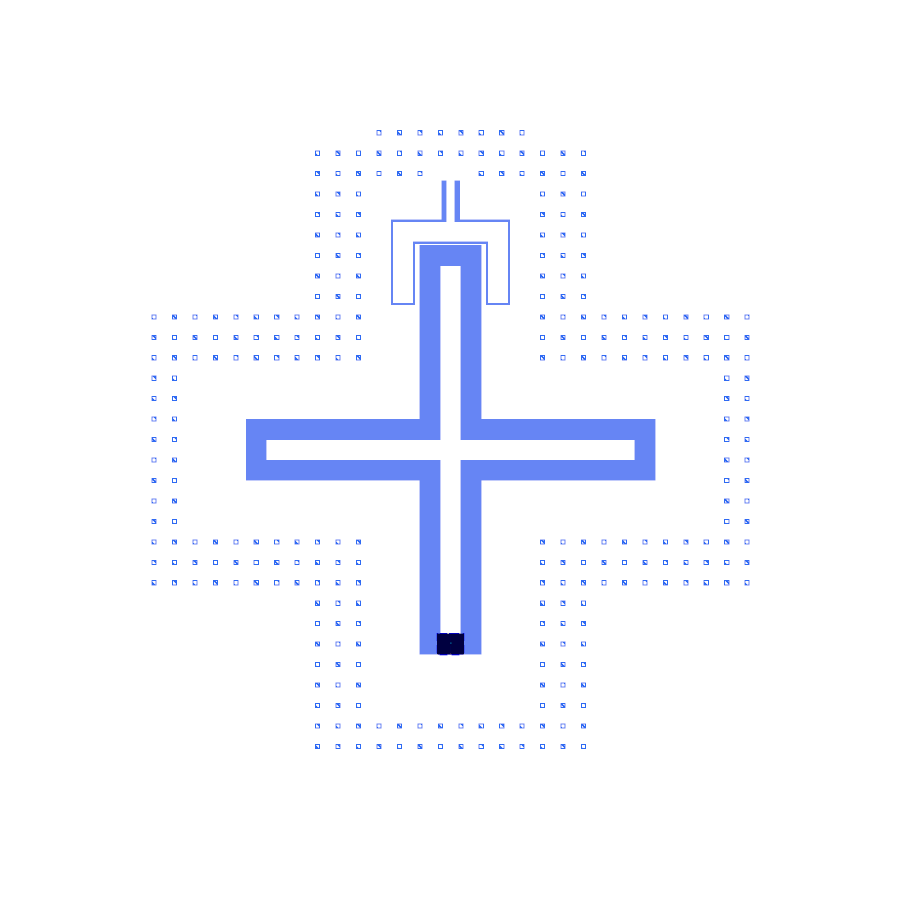

WindowsPath('examples/tutorials/img/t00_qubit.png')

In [10]:
T.md(T.drc_md(T.drc(d)))
T.snap(d, "qubit", box=(2425, 1550, 3525, 2650), size=(900, 900), width=360)

## 6 · The readout resonator (a λ/4 hanger)

A route from the claw to `fl.hanger(...)` is a λ/4 resonator: its far end is a coupler running along the feedline
(`length` µm), shorted at one end. `near=(x, y)` centres the coupler at the feedline point nearest to (x, y), so it
stays put if the feedline's start moves (e.g. when a pad slides to the edge); `meander=` sets the drawn length (a KQC
`Meander`, tuned to the exact length). The length comes from the target: λ/4 = v_ph / 4f on the PDK stack.

R1: 4501 µm (v_ph = 0.4204 c)


**DRC clean** — 0 errors, 0 warnings, 0 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| – | – | 0 | – |

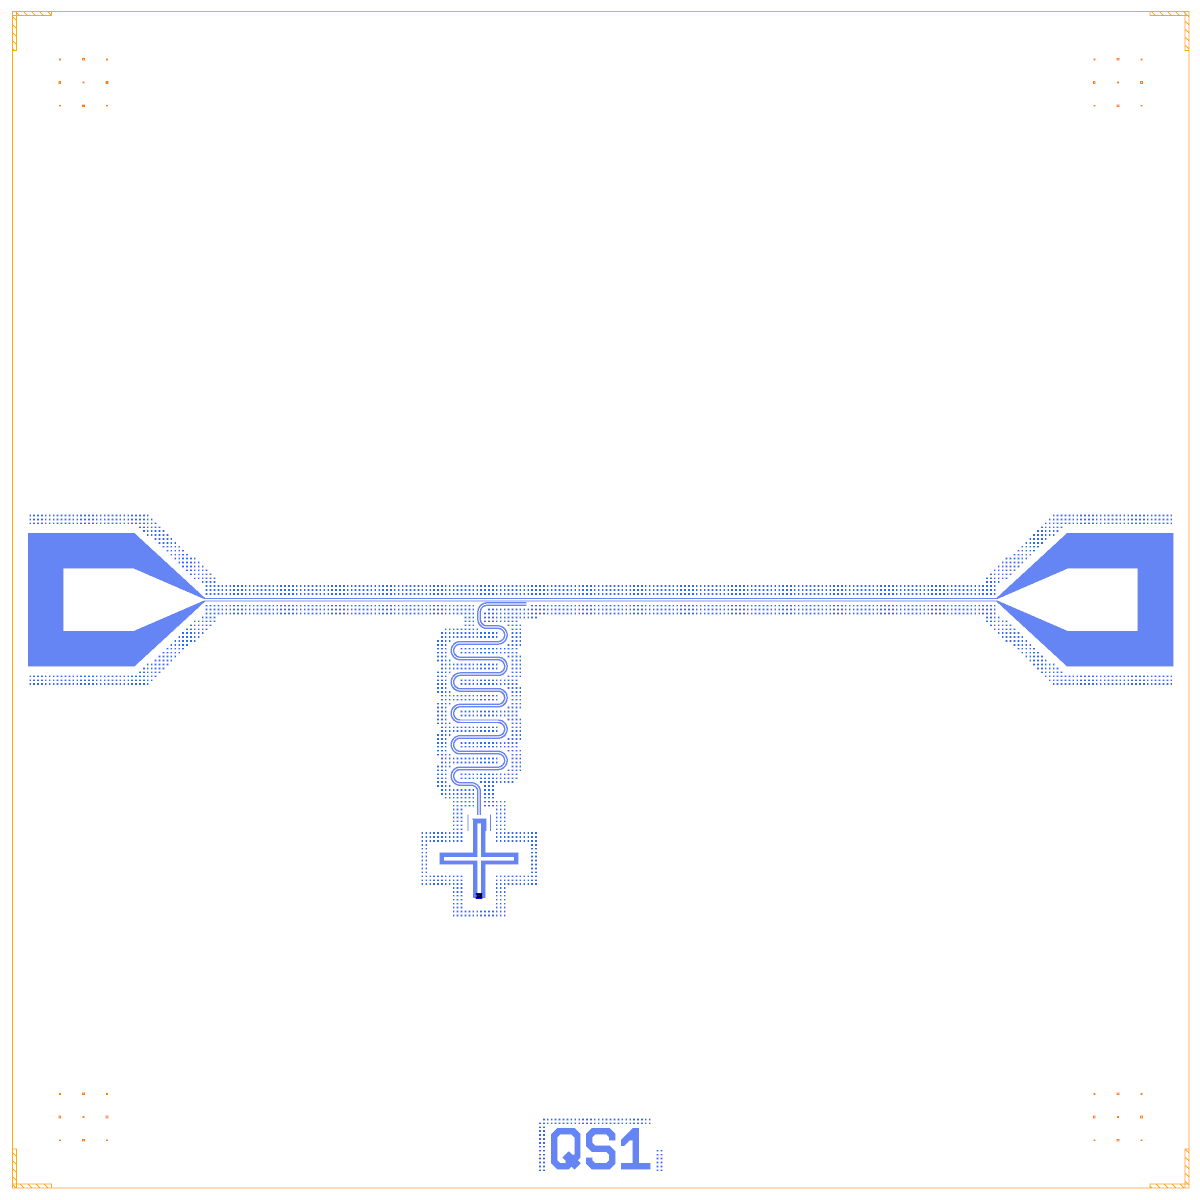

WindowsPath('examples/tutorials/img/t00_chip.png')

In [11]:
from quantcore_circuits.circuit.bridges import tl_resonator

vp = tl_resonator(4500, pdk.cpw_a, pdk.cpw_b)["vp_m_s"]
L_R1 = vp / (4 * F_R * 1e9) * 1e6                 # bare λ/4 for 7.0 GHz (µm)
r1 = d.route("R1", q1.claw_n, fl.hanger(near=(3125, 3750), length=300, side="right"), meander=L_R1, r=50)
d.targets(Q1={"f_q_GHz": F_Q}, R1={"f_GHz": F_R})
print(f"R1: {L_R1:.0f} µm (v_ph = {vp / 2.998e8:.4f} c)")
rep = T.drc(d)
T.md(T.drc_md(rep))
T.snap(d, "chip", size=(1200, 1200), width=480)

## 7 · Netlist and LOM simulation

The netlist is the layout's connectivity: pads → 50 Ω ports on `FL`; the qubit → island `Q1` (C to ground, JJ to
ground, C_g to the claw); `R1` → a λ/4 `TLres` from the claw node to ground plus a `HANGER` κ element to `FL`.

`simulate(fill(model, design))` runs QuCat on the whole circuit (normal modes, κ through the 50 Ω ports) and QuTiP
on the leading modes (dressed f_q, α, f_r, χ). Without FEM, the element values are the component estimates
(`lom/calibration.py`).

In [12]:
lb = d.lom()
C.show_netlist(lb)
res = C.simulate_lom(lb, d.design)
T.md(C.modes_md(res))
T.md(C.summary_md(res, d.data["targets"]))

**4 nodes · 8 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `Q1` | `Q1.island` |
| `Q1.claw_n` | `Q1.claw_n` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 96.1 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.87 nH, Cj 14.7 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `Q1.claw_n` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `Q1.claw_n` – `gnd` | 76.4 fF |
| `R1` | TLres | `Q1.claw_n` – `gnd` | lambda/4, 4501 µm, 7.000 GHz |
| `K_R1` | HANGER | `Q1.claw_n` – `FL` | κ 0.214 MHz (L 300 µm) |

**Unconnected ports:** none

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.6847 | 0.000558 | 167.8 | J_Q1 0.99 |
| R1 | resonator | 6.2527 | 0.135 | 0.0 | R1 0.99 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.51 | 5.5 |
| `Q1.alpha_MHz` | -182.18 | – |
| `R1.chi_MHz` | -1.1288 | – |
| `R1.f_GHz` | 6.2518 | 7 |
| `R1.kappa_MHz` | 0.13536 | – |

The qubit lands near its target. The resonator does not: the claw (≈ 80 fF at the open end) loads the λ/4, so f_r
sits below the bare-line 7.0 GHz. That is the next step.

## 8 · Iterate: one geometry change, new values

Shorten R1 by the ratio of the simulated to the target frequency, rebuild, re-run the LOM; repeat until f_r is within
0.2 %. Only the meander length changes; the layout (live: in KLayout), the DRC and every value downstream follow.
The claw loading does not scale exactly with the length, so it takes two or three steps.

In [13]:
keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
before, length, res2 = T.lom_params(res, keys), L_R1, res
for step in range(1, 5):
    f_r = res2.params["R1.f_GHz"]
    if abs(f_r / F_R - 1) < 0.002:
        break
    length *= f_r / F_R                           # λ/4 ∝ 1/f: scale the drawn length
    r1.set(meander=length)                        # one change → one rebuild (live: KLayout redraws the meander)
    res2 = C.simulate_lom(d.lom(), d.design)
    print(f"step {step}: R1 {length:.0f} µm → f_r {res2.params['R1.f_GHz']:.4f} GHz")
after = T.lom_params(res2, keys)
T.md(T.before_after_md(before, after))

step 1: R1 4020 µm → f_r 6.9153 GHz
step 2: R1 3971 µm → f_r 6.9904 GHz


| quantity | before | after | change |
|---|---|---|---|
| `Q1.f_q_GHz` | 5.51 | 5.511 | +0.001003 (+0.0 %) |
| `Q1.alpha_MHz` | -182.18 | -182.88 | -0.702 (-0.4 %) |
| `R1.f_GHz` | 6.2518 | 6.9904 | +0.7387 (+11.8 %) |
| `R1.chi_MHz` | -1.1288 | -0.43 | +0.6988 (+61.9 %) |
| `R1.kappa_MHz` | 0.13536 | 0.18728 | +0.05192 (+38.4 %) |

> **Simulation PC (32 GB+ RAM).** The cells below solve the three FEM jobs of the Q1 + R1 subset (Q3D, eigenmode + EPR, driven) in AEDT at converged settings, and re-solve the kept results on today's library (`RESOLVE = True`). On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 9 · FEM stage 1: the subset check (one sim group, three analyses)

A **sim group** is a FEM sub-problem: the selected instances and routes plus a margin. `Q1R1` is the qubit and its
readout with 300 µm around them. Each analysis builds its own job from the group (`C.export_sims` →
`build/jobs/t00_quickstart_Q1R1_<analysis>/`): KQC cuts the box out of the chip (no cheese, no frame, airbridges
dropped), `qcc` names every net after its LOM node and adds the ports.

| analysis | what the box holds | ports | gives |
|---|---|---|---|
| `q3d_cmatrix` (Q3D) | Q1 and a 100 µm stub of R1: the route is cut at the claw, so the claw is its own net | the claw stub | Maxwell C: island, claw, C_g → the LOM's three capacitances |
| `eigenmode_epr` (HFSS eigenmode + pyEPR) | Q1, the whole R1 and the stretch of feedline the box cuts | junction = lumped L_J ‖ C_J; each cut feedline end = 50 Ω | f_q, f_r, p_J; pyEPR dressed f, α, χ; Q → κ |
| `hfss_driven` (HFSS driven, terminal) | as the eigenmode | junction = lumped L_J ‖ C_J; the cut feedline ends = wave ports | S21 notch → f_r, κ_ext, Q_i |

The recipe comes from the FEM-loop milestone (`examples/fem_loop/`):

- the eigenmode asks for **3 modes above 4 GHz**: the qubit, R1 and a spare slot (a cut feedline can bring a low-Q
  mode of its own);
- the driven run needs a **10 µm mesh seed on the gaps** (`mesh_size={"1t1_gap": 10}`): without it the adaptive mesh
  never refines the off-resonance resonator and S21 stays flat. The fast sweep covers f_r − 400 … + 200 MHz with
  20 001 points (≈ 30 kHz apart; κ is ≈ 0.2 MHz). AEDT refuses more than 25 000 points;
- passes are capped so each solve fits this workstation (see the wall times below).

**`FEM_FAST`** (first line of the next cell, default `True`): every job is exported with the library's fast test settings (`sim_tools.export.FAST_SETTINGS`: Q3D 2 % / ≤ 8 passes, eigenmode ΔF 1 % / ≤ 3 passes (memory-bound here), driven ΔS 0.05 / ≤ 6 passes, mesh seeds × 3 (none given: a 40 / 30 µm gap seed for eigenmode / driven), sweeps ≤ 10 001 points), so the whole chain (solve → keep → bring back → feedback → re-solve) runs in minutes. The values are not converged; they move with the design. `False` exports the settings as written for a production run (kept results of a full solve also stand in for a fast re-run of the same design).

In [14]:
FEM_FAST = T.fem_fast(FEM_FAST)                   # the switch from the top: fast test settings, or as below
SIM = {  # solver settings per analysis (the fem_loop recipe)
    "q3d_cmatrix": {"percent_error": 0.5},
    "eigenmode_epr": {"n_modes": 3, "min_frequency": 4.0, "max_delta_f": 0.2, "maximum_passes": 14},
    "hfss_driven": {"mesh_size": {"1t1_gap": 10}, "frequency": F_R, "minimum_passes": 3, "maximum_passes": 10,
                    "sweep_start": F_R - 0.4, "sweep_end": F_R + 0.2, "sweep_count": 20001, "sweep_type": "fast"},
}
# SIM_SUBSET → the sim group: [("Q1", "R1")] is the group "Q1R1" (Q1 + R1 + 300 µm; the box cuts the feedline);
# "whole" → the built-in group "chip"
GROUP = T.sim_subset(d, SIM_SUBSET, name="Q1R1", margin_um=300, analyses=list(SIM), settings=SIM)[0]
DESIGN = d.save(T.DESIGNS / "t00_quickstart.json")
jobs = {a: C.export_sims(DESIGN, [GROUP], a)[GROUP] for a in SIM}   # "send": one job folder per analysis
T.md(C.jobs_md({f"{GROUP} · {a}": job for a, job in jobs.items()}))

FEM_FAST: jobs are exported with the fast test settings (q3d_cmatrix percent_error 2, maximum_passes 8, minimum_passes 1; hfss_driven max_delta_s 0.05, maximum_passes 6, minimum_passes 1; eigenmode_epr max_delta_f 1, maximum_passes 3, minimum_passes 1); values are not converged


**SIM_SUBSET = [('Q1', 'R1')]** → 1 box(es); each is rendered and simulated on its own, and its values fill only these components of the whole-chip netlist:

| group (box) | qubits | readout chain | buses in | buses cut at the qubit | feedline (cut by the box) |
|---|---|---|---|---|---|
| `Q1R1` | Q1 | Q1: R1 | – | – | FL |

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · q3d_cmatrix | `build/jobs/t00_quickstart_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.claw_n` | `Q1.island`, `Q1.claw_n` |
| Q1R1 · eigenmode_epr | `build/jobs/t00_quickstart_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FL`<br>3 · edge_lumped · `FL` | `Q1.island`, `FL`, `FL#2` |
| Q1R1 · hfss_driven | `build/jobs/t00_quickstart_Q1R1_hfss_driven` | 1 · junction · `Q1.junction`<br>2 · edge · `FL`<br>3 · edge · `FL` | `Q1.island`, `FL` |

### Solve (`RUN_FEM`)

`RUN_FEM = True` solves each job with `sim_tools.hfss.solve_job`: a **new** non-graphical AEDT 2024 R1 batch process
per job, one after the other. It never attaches to an AEDT window you have open, and on a timeout qcc stops only the
process tree it started. `RUN_FEM = {"q3d_cmatrix"}` solves only the listed analyses.

Each solved job's `results.json` + `job.json` are copied to `examples/tutorials/fem/<job>/`, and the cells below read
them from there, so they work without AEDT. `RESOLVE = True` re-solves even then (after a library fix, say). A kept result of the *same* job (same design hash and settings) is not
solved again. Wall times on this workstation are in the table.

**`AEDT_MODE`** (next to `RUN_FEM`): `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

In [15]:
# RUN_FEM, AEDT_MODE: the switches at the top (SIM_SUBSET cell)
TIMEOUT = {"q3d_cmatrix": 900, "eigenmode_epr": 2400, "hfss_driven": 2700}   # s
keep = {a: T.solve_or_load(jobs[a][0], RUN_FEM, timeout=TIMEOUT[a], force=RESOLVE, aedt=AEDT_MODE) for a in SIM}
# the subset check, FEM only: convergence, the raw C-matrix / eigenmodes / S21 notches, the filled C vs the estimates
CHECK = T.subset_check(keep, d.lom().model, DESIGN)

t00_quickstart_Q1R1_q3d_cmatrix: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t00_quickstart_Q1R1_eigenmode_epr: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True
t00_quickstart_Q1R1_hfss_driven: the kept results were solved for another revision of this job (design hash or settings differ); they are shown as they are — re-solve with RUN_FEM = True


| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| q3d_cmatrix | 7 | 4280 | Delta % | 1.94 / 2.0 | False | 41.6 |
| eigenmode_epr | 3 | 130307 | Max Delta Freq. % | 3.14 / 1.0 | False | 392.8 |
| hfss_driven | 2 | 96137 | Max Mag. Delta S | 0.0476 / 0.05 | True | 167.3 |

Q3D C-matrix of `t00_quickstart_Q1R1_q3d_cmatrix` (2024.1.0, 41.6 s; Maxwell form, fF):

| net | `Q1.island` | `Q1.claw_n` |
|---|---|---|
| `Q1.island` | 101.359 | -2.943 |
| `Q1.claw_n` | -2.943 | 84.030 |

Eigenmodes of `t00_quickstart_Q1R1_eigenmode_epr` (2024.1.0, 392.8 s):

| mode | f linear (GHz) | Q | p_J | f dressed, pyEPR (GHz) | self-Kerr χ_mm (MHz) |
|---|---|---|---|---|---|
| 1 | 5.3043 | 1.211e+06 | 0.9852 | 5.1565 | -153.4 |
| 2 | 6.8555 | 2.326e+04 | 0.0006 | 6.8554 | -0.0 |
| 3 | 15.6251 | 3.342e+06 | 0.0000 | 15.6251 | 0.0 |

Cross-Kerr (dispersive shift) χ₁₂ = -0.189 MHz (pyEPR, numerical diagonalisation).

Convergence: 3 passes, 130307 tets, last Max Delta Freq. % 3.1392 (target 1.0), converged: False.

Driven S-parameters of `t00_quickstart_Q1R1_hfss_driven` (2024.1.0, 167.3 s; ports ['FL', 'FL'], 10001 points over [6.6, 7.2] GHz):

| notch | f0 (GHz) | κ_ext/2π (MHz) | Q_c | Q_i | depth | fit residual |
|---|---|---|---|---|---|---|
| S21 | 6.69769 | 0.3213 | 2.085e+04 | 1.11e+06 | 0.891 | 0.00024 |

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|
| `C_Q1` | Q1 – gnd | 96.07 | 98.42 | `t00_quickstart_Q1R1_q3d_cmatrix` |
| `Cg_Q1_claw_n` | Q1 – Q1.claw_n | 3.17 | 2.943 | `t00_quickstart_Q1R1_q3d_cmatrix` |
| `Cc_Q1_claw_n` | Q1.claw_n – gnd | 76.4 | 66.69 | `t00_quickstart_Q1R1_q3d_cmatrix` |

**3** branches filled from FEM; **1** kept their estimates (0 outside the subset).
- `t00_quickstart_Q1R1_q3d_cmatrix` (group `Q1R1`, q3d_cmatrix): 3 branches; scope Q1, R1

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

> **Simulation PC (32 GB+ RAM).** The cells below fill the whole LOM from the solved subset and compare LOM with FEM; this is the LOM calibration step (hanger κ, claw, χ), which needs fresh converged FEM results. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 10 · FEM stage 2: the subset values in the whole LOM, LOM vs FEM

Here the subset box `Q1R1` is the whole chip minus its two pads (the LOM has the pads as 50 Ω ports), so stage 2 uses
the stage-1 jobs: the whole netlist is filled from them and simulated.

**(a) The C-matrix.** `fill(model, design, job)` replaces each capacitance estimate by the C-matrix value of the same
net (`Q1.island`, `Q1.claw_n`): island → ground, island → claw (C_g) and claw → ground (the check above shows them).
Then the same LOM simulation runs on the FEM values.

In [16]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

KEYS = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
model = d.lom().model
est = simulate(fill(model, DESIGN), max_modes=2)  # LOM on the component estimates (= section 8's last step)
fem_q3d = None
if keep["q3d_cmatrix"]:
    filled = fill(model, DESIGN, keep["q3d_cmatrix"])   # the whole netlist (the stage-1 table shows its C values)
    fem_q3d = simulate(filled, max_modes=2)
    T.md(T.fem_vs_lom_md([(k, est.params.get(k), fem_q3d.params.get(k), "LOM on the Q3D C-matrix") for k in KEYS]))
else:
    print("No Q3D results kept: RUN_FEM = True in section 9 solves the job.")

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q1.f_q_GHz | 5.511 | 5.462 | -0.9 % | LOM on the Q3D C-matrix |
| Q1.alpha_MHz | -182.9 | -179.5 | +1.8 % | LOM on the Q3D C-matrix |
| R1.f_GHz | 6.99 | 7.086 | +1.4 % | LOM on the Q3D C-matrix |
| R1.chi_MHz | -0.43 | -0.3159 | +26.5 % | LOM on the Q3D C-matrix |
| R1.kappa_MHz | 0.1873 | 0.1978 | +5.6 % | LOM on the Q3D C-matrix |

**(b) The eigenmodes** (their table is in the stage-1 check). The eigenmode job is compared directly: each mode's linear frequency and Q, and pyEPR's
dressed frequencies, α and χ from the junction's energy participation p_J (`analysis.epr`, evaluated inside qcc's own
AEDT run). The qubit mode has the largest p_J; the resonator mode is the other mode nearest the LOM's f_r. Its Q with
both feedline ends terminated in 50 Ω is the external Q (bulk-dielectric loss removed), so κ = f/Q.

In [17]:
import json
from quantcore_circuits.analysis.results import fem_kappa

fem_eig = {}
if keep["eigenmode_epr"]:
    res_eig = json.loads((keep["eigenmode_epr"] / "results" / "results.json").read_text(encoding="utf-8"))
    epr, modes = res_eig.get("epr") or {}, res_eig["eigenmodes"]
    iq = max(range(len(modes)), key=lambda i: epr["p_mj"][i][0]) if epr.get("p_mj") else 0
    ir = min((i for i in range(len(modes)) if i != iq), key=lambda i: abs(modes[i]["f_GHz"] - est.params["R1.f_GHz"]))
    kap = fem_kappa({"eigenmodes": modes, "epr": epr}, {"R1": modes[ir]["f_GHz"]}).get("R1", {})
    fem_eig = {"Q1.f_q_GHz": epr["f_GHz"][iq] if epr else modes[iq]["f_GHz"],
               "Q1.alpha_MHz": epr["chi_MHz"][iq][iq] if epr else None,
               "R1.f_GHz": epr["f_GHz"][ir] if epr else modes[ir]["f_GHz"],
               "R1.chi_MHz": epr["chi_MHz"][iq][ir] if epr else None, "R1.kappa_MHz": kap.get("kappa_MHz")}
    T.md(T.fem_vs_lom_md([(k, est.params.get(k), fem_eig.get(k), "FEM eigenmode + pyEPR") for k in KEYS]))
else:
    print("No eigenmode results kept: RUN_FEM = True in section 9 solves the job.")

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q1.f_q_GHz | 5.511 | 5.157 | -6.4 % | FEM eigenmode + pyEPR |
| Q1.alpha_MHz | -182.9 | -153.4 | +16.1 % | FEM eigenmode + pyEPR |
| R1.f_GHz | 6.99 | 6.855 | -1.9 % | FEM eigenmode + pyEPR |
| R1.chi_MHz | -0.43 | -0.1889 | +56.1 % | FEM eigenmode + pyEPR |
| R1.kappa_MHz | 0.1873 | 0.2886 | +54.1 % | FEM eigenmode + pyEPR |

**(c) The driven S21** (its notch fit is in the stage-1 check). The two cut ends of the feedline are wave ports; R1 is a notch in S21. `fit_notches` fits
one notch per resonator (`analysis.results`): f0, the loaded and coupling Q, κ_ext = f0/Q_c, and Q_i (here limited by
the sapphire loss tangent). κ_ext is what the LOM's hanger element estimates (`HANGER_K`, calibrated on an earlier
driven run).

In [18]:
fem_drv = {}
if keep["hfss_driven"]:
    res_drv = json.loads((keep["hfss_driven"] / "results" / "results.json").read_text(encoding="utf-8"))
    notches = list(((res_drv.get("sparams") or {}).get("notch") or {}).values())
    if notches:
        notch = min(notches, key=lambda n: abs(n["f0_GHz"] - est.params["R1.f_GHz"]))
        fem_drv = {"R1.f_GHz": notch["f0_GHz"], "R1.kappa_MHz": notch["kappa_ext_MHz"]}
        T.md(T.fem_vs_lom_md([(k, est.params.get(k), fem_drv.get(k), "FEM driven S21 notch fit")
                              for k in ("R1.f_GHz", "R1.kappa_MHz")]))
else:
    print("No driven results kept: RUN_FEM = True in section 9 solves the job.")

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| R1.f_GHz | 6.99 | 6.698 | -4.2 % | FEM driven S21 notch fit |
| R1.kappa_MHz | 0.1873 | 0.3213 | +71.5 % | FEM driven S21 notch fit |

> **Simulation PC (32 GB+ RAM).** The cells below feed the FEM point back (analyse, surrogate, next revision); the loop is only meaningful on converged FEM results, so run it after the solves above. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 11 · Feedback: FEM point → surrogate → the next revision

`loop.analyse` puts every result into one consensus: the Q3D C-matrix fills the circuit, the eigenmode's EPR adds the
`pyepr` estimator, the driven fit fills the hanger's κ (`combine_jobs` merges the three jobs into one folder). The
estimators (QuCat, SQcircuit, scqubits, Metal LOM, pyEPR) run on the filled circuit and each target gets a chosen
value.

`loop.feedback` then anchors a surrogate on that point (each capacitance a power law of its knob, scaled so it is
exact at the measured point), solves for the knobs that put every target inside its tolerance, and writes the next
revision (`build/t00_quickstart/revisions/rev1.json`, built and netlist-checked). The junction knob is bounded to the
PDK window (R_n 40–50 kΩ → L_J ≈ 6.0–7.5 nH). Tutorial 4 closes the loop: rebuild → re-simulate → feedback again.

In [19]:
from quantcore_circuits import loop
from quantcore_circuits.analysis.results import combine_jobs
from quantcore_circuits.assembly.drc import check
from quantcore_circuits.circuit.consensus import report_markdown

if keep["q3d_cmatrix"]:
    others = [keep[a] for a in ("eigenmode_epr", "hfss_driven") if keep[a]]
    job = combine_jobs(keep["q3d_cmatrix"], others, "build/jobs/t00_quickstart_Q1R1_combined", same_design=False)
else:
    job = None                                    # nothing solved: the consensus of the LOM estimates
an = loop.analyse(DESIGN, job, group="Q1R1", readout=False)
T.md(report_markdown(an.rows, "Q1 / R1 consensus" + (" on the FEM values" if job else " (LOM estimates only)")))
prop, rev, rev_build = loop.feedback(an, design_source=DESIGN, bounds={"Q1.junction.Lj_nH": (6.0, 7.5)})
T.md("| knob | now | proposed |\n|---|---|---|\n" + "\n".join(
    f"| `{k}` | {prop.start_knobs[k]:.5g} | {v:.5g} |" for k, v in prop.knobs.items()))
now = {r.param: r.chosen for r in an.rows}
T.md(T.before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals}))
print("revision:", rev, "· DRC:", "clean" if check(rev_build).ok else "ERRORS")

# Q1 / R1 consensus on the FEM values

| parameter | metal_lom | pyepr | qucat | qutip | scqubits | sqcircuit | chosen | spread | target | residual/tol | status |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Q1.EC_GHz (GHz) | 0.1671 | – | 0.1669 | – | 0.1669 | 0.1669 | **0.1671** (metal_lom) | 0.09 % | – | – | unknown |
| Q1.EJ_GHz (GHz) | 23.79 | – | 23.79 | – | 23.79 | 23.79 | **23.79** (metal_lom) | 0.00 % | – | – | unknown |
| Q1.alpha_MHz (MHz) | -179.7 | -153.4 | -179.5 | -179.5 | -179.5 | -179.5 | **-153.4** (pyepr) | 15.00 % ⚑ | – | – | unknown |
| Q1.f_q_GHz (GHz) | 5.465 | 5.157 | 5.463 | 5.463 | 5.462 | 5.463 | **5.157** (pyepr) | 5.69 % ⚑ | 5.5 ± 0.02 | -17.17 | fail |
| R1.chi_MHz (MHz) | -0.3374 | -0.1889 | -0.3101 | -0.3101 | -0.3199 | -0.3101 | **-0.1889** (pyepr) | 50.16 % ⚑ | – | – | unknown |
| R1.f_GHz (GHz) | 7.116 | 6.855 | 7.116 | 7.116 | 7.116 | 7.116 | **6.855** (pyepr) | 3.69 % ⚑ | 7 ± 0.01 | -14.46 | fail |
| R1.g_MHz (MHz) | 32.91 | – | – | 45.17 | 45.88 | – | **32.91** (metal_lom) | 31.40 % ⚑ | – | – | unknown |
| R1.kappa_MHz (MHz) | – | 0.3213 | – | – | – | – | **0.3213** (pyepr) | – | – | – | unknown |


| knob | now | proposed |
|---|---|---|
| `Q1.cross_length` | 450 | 450 |
| `Q1.claw_length` | 100 | 100 |
| `Q1.junction.Lj_nH` | 6.8719 | 6.064 |
| `R1.length` | 3971.5 | 3880.7 |

| quantity | before | after | change |
|---|---|---|---|
| `Q1.f_q_GHz` | 5.1565 | 5.4999 | +0.3434 (+6.7 %) |
| `R1.f_GHz` | 6.8554 | 7 | +0.1446 (+2.1 %) |

revision: build\t00\revisions\rev1.json · DRC: clean


## 12 · Fab export: cheese, rounding, 3/0

`export_fab(result, path)` writes only the PDK fab layers (flat). It keeps the cheese the build drew — the PDK band
of 5 µm squares around the 3/0 keep-outs (this design has no cheese of its own) — and rounds every corner with a
radius tied to the polygon's shortest dimension. 3/0 (the filled second-metal keep-out) is derived here. The CLI does
the same: `qcc mask examples/tutorials/designs/t00_quickstart.json` (`--no-cheese`, `--no-round` switch the rules
off).

`build/t00_quickstart_fab.oas`: cheese **build** (2772 holes)

| fab layer | polygons |
|---|---|
| `CHIP_BOUNDARY` | 1 |
| `HSQ` | 2 |
| `JJ_BENT` | 1 |
| `JJ_STRAIGHT` | 1 |
| `M1` | 2778 |
| `M3` | 2776 |
| `MARKERS_ALIGN` | 36 |
| `MARKERS_DICING` | 4 |
| `SPACER_1` | 2 |
| `SPACER_2` | 2 |
| `SPACER_3` | 2 |

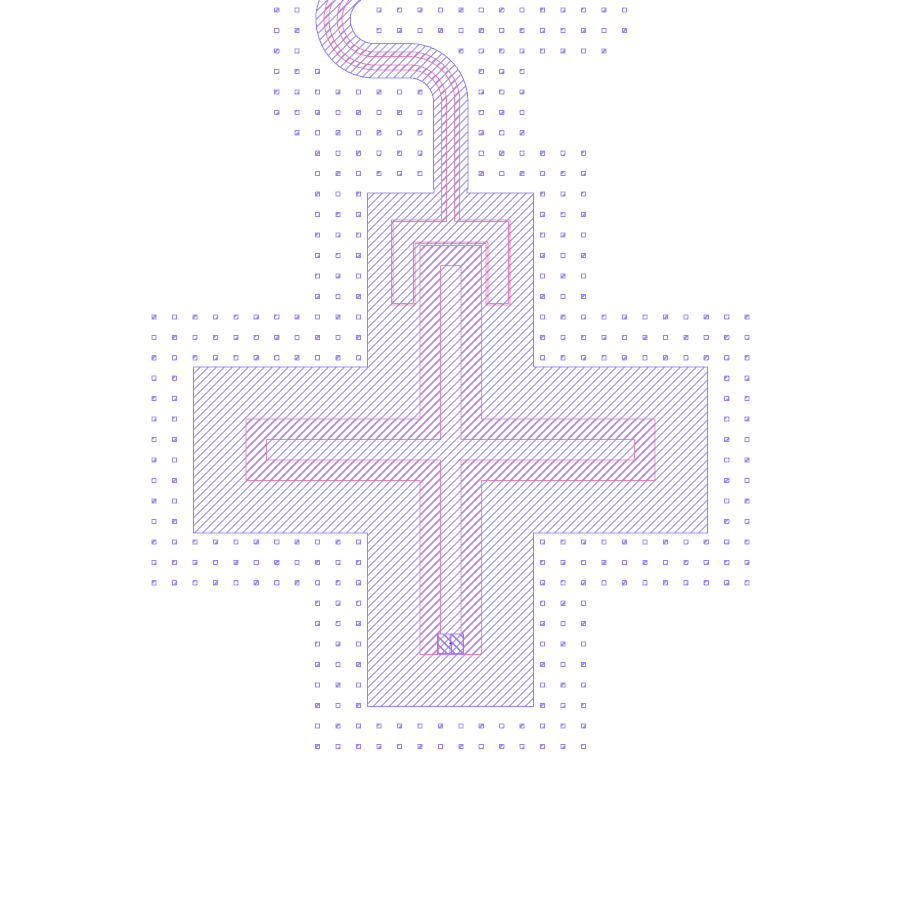

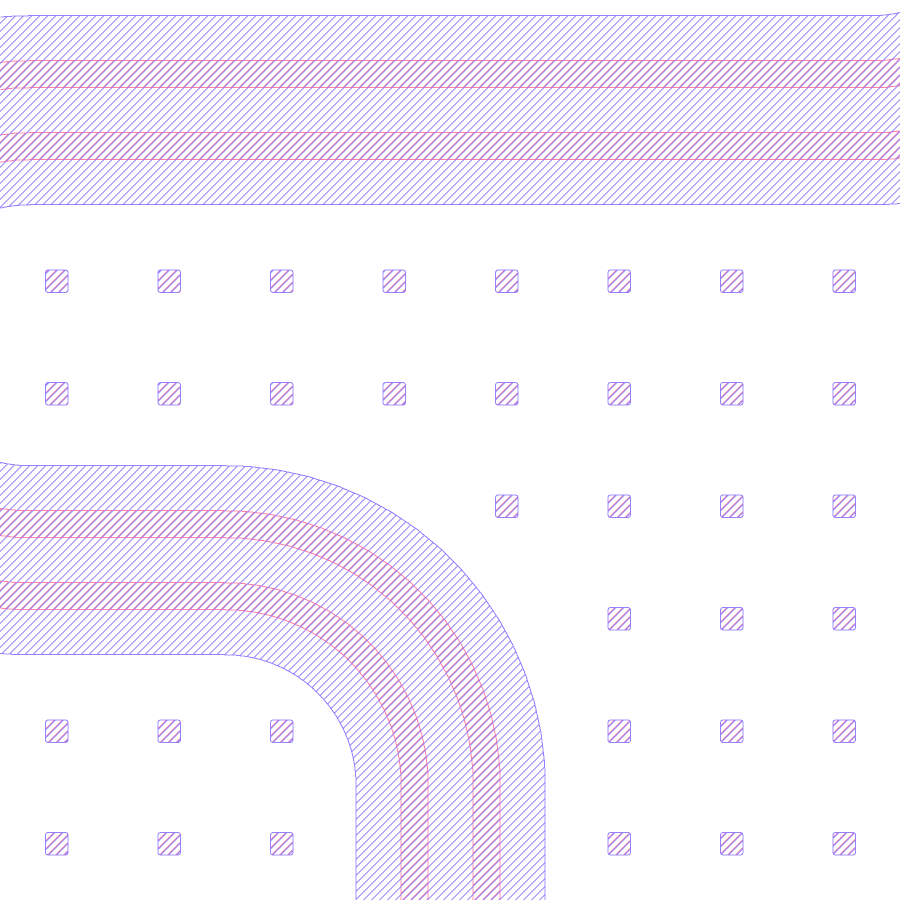

WindowsPath('examples/tutorials/img/t00_fab_claw.png')

In [20]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

report = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fab = export_fab(T.built(d), "build/t00_quickstart_fab.oas", report=report)
T.md(T.fab_report_md(report, fab))
T.snap(d, "fab_qubit", box=(2425, 1550, 3525, 2650), size=(900, 900), width=420, source=fab)  # 1/0, 3/0, cheese
T.snap(d, "fab_claw", box=(2875, 2500, 3075, 2700), size=(900, 900), width=420, source=fab)  # rounding, cheese squares

## 13 · Snapshots and the KLayout window

The pictures above are headless renders (`live.snapshot.snapshot`). In a live session the Quantcore plugin can also
screenshot the KLayout window itself (`gui_snapshot`, command port 8083); without the plugin or KLayout it falls back
to the headless render.

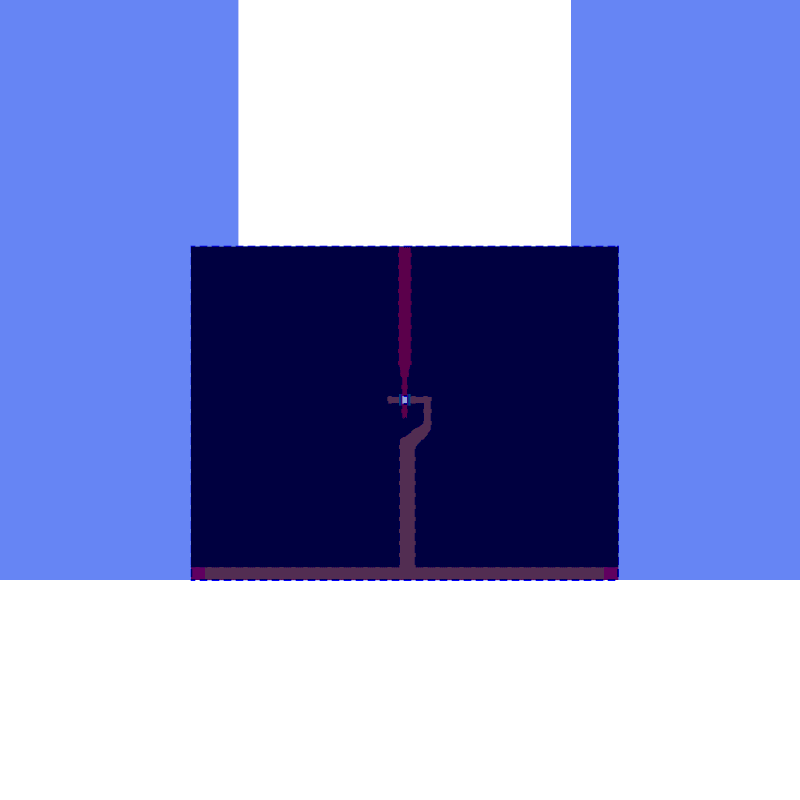

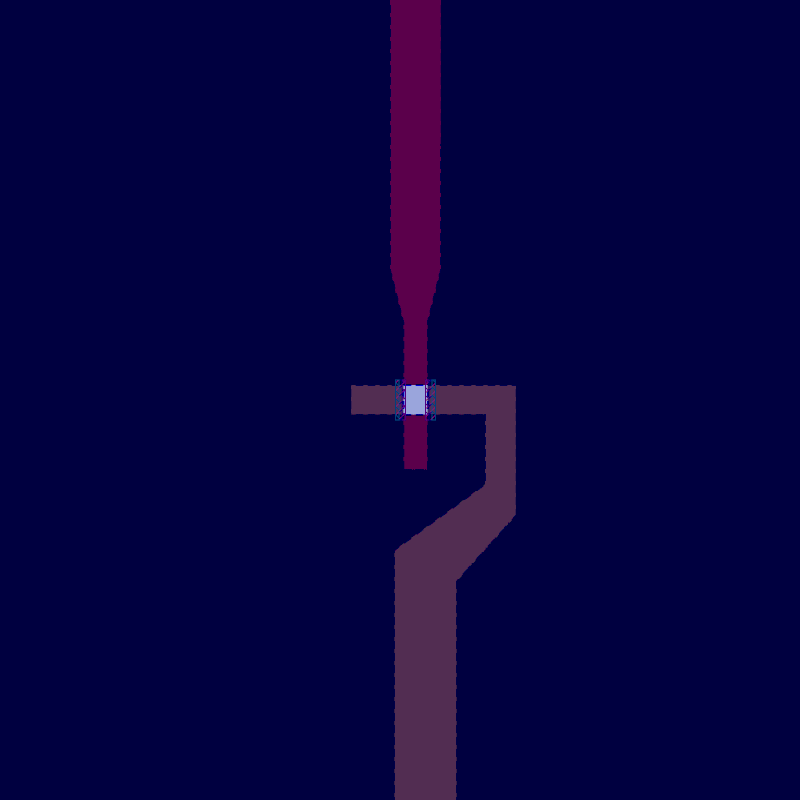

changes sent so far: ['add PAD_W (BondPad)', 'add PAD_E (BondPad)', 'route FL', 'add Q1 (Xmon)', 'set Q1', 'route R1', 'targets', 'set R1', 'set R1', 'sim group Q1R1']


In [21]:
T.snap(d, "junction_leads", box=T.junction_box(d, "Q1", half=30), size=(800, 800), width=320)  # leads + overlap
T.snap(d, "junction", box=T.junction_box(d, "Q1"), size=(800, 800), width=320)   # the finger overlap, spacer
if LIVE:
    from quantcore_circuits.live.snapshot import gui_snapshot
    png, how = gui_snapshot(T.IMG / "t00_klayout_window.png", (1200, 900), layout=d.out)
    print("KLayout screenshot:", how)
print("changes sent so far:", d.history)

## 14 · Summary

| step | here |
|---|---|
| PDK | sapphire 650 µm, Nb trilayer junctions, QCT frame, 100 µm pad rule, cheese band, rounding |
| layout | 2 pads (at the edge), feedline, Xmon, λ/4 hanger readout; live in KLayout via KLive or headless |
| DRC | clean; warnings explained as they appear |
| LOM | island + junction + claw + λ/4 + hanger κ; QuCat + QuTiP values next to the targets |
| iterate | the resonator length, rescaled two or three times, put f_r on target |
| FEM | stage 1, the subset check (FEM only): one sim group `Q1R1` (here the chip minus its pads), three jobs: Q3D C-matrix, eigenmode/EPR (3 modes), driven S21 (10 µm gap seed); `RUN_FEM = True` solves them in new batch AEDT processes; kept in `examples/tutorials/fem/` |
| stage 2 | C-matrix → `fill` (the whole netlist) → LOM on FEM values; pyEPR f_q, α, f_r, χ, κ; S21 notch → f_r, κ_ext; all next to the LOM estimates |
| feedback | `combine_jobs` → `loop.analyse` (one consensus) → `loop.feedback` → revision 1 (built, DRC clean) |
| fab | `export_fab`: fab layers, PDK cheese band, rounded corners |

**CLI equivalents:** `qcc build examples/tutorials/designs/t00_quickstart.json --show` (build + KLive),
`qcc watch <design.json>` (rebuild on every save), `qcc design drc`, `qcc circuit export` / `qcc circuit simulate`,
`qcc sim build <design> -g Q1R1 -a q3d_cmatrix`, `qcc hfss render <design> -g Q1R1 -a q3d_cmatrix --solve`,
`qcc mask <design>`.

Next: **Tutorial 1** (`01_chip12_coupled_chip.ipynb`) rebuilds a real nine-qubit chip and runs the FEM round trip.